# Differential equations 2: Linear first-order equations

*Learning path: differential equations, part 2 of 8.* [Index](README.md) · Previous: [First-order equations](01-first-order-equations.ipynb) · Next: [Second-order equations and oscillations](03-second-order.ipynb)

Salt water flows into a tank while the mixture flows out. A capacitor charges through a resistor while an alternating
voltage drives it. A skydiver speeds up until air resistance balances gravity. These all lead to the same kind of
equation,

$$y' + p(x)\,y = q(x),$$

which is **linear** in $y$: no $y^2$, no $\sin y$. Linear first-order equations can always be solved, by one trick:
the integrating factor. And their solutions always split the same way, into a part that remembers the start and fades,
and a part that follows the input.

**Who this is for.** You have done [lesson 1](01-first-order-equations.ipynb), and know the product rule and
integration by parts.

**What you will be able to do afterwards:**

1. solve $y' + p\,y = q$ with an integrating factor, by hand;
2. set up and solve a mixing problem from "rate in minus rate out";
3. split a solution into a transient and a steady state, and find the amplitude and lag of the response to a
   sinusoidal input;
4. explain Euler's method and why its error halves when the step halves.

Plan about an hour.

## 1. The integrating factor

Take $y' + 2y = e^{-x}$. The left side is almost the derivative of a product. Multiply the whole equation by
$\mu = e^{2x}$:

$$e^{2x}y' + 2e^{2x}y = e^{x}, \qquad\text{and the left side is exactly}\qquad (e^{2x}y)'.$$

So $(e^{2x}y)' = e^x$, integrate: $e^{2x}y = e^x + C$, and $y = e^{-x} + Ce^{-2x}$. In general, for $y' + p\,y = q$,
the **integrating factor** is $\mu = e^{\int p\,dx}$, chosen so that $\mu' = p\mu$, and then

$$(\mu y)' = \mu q, \qquad y = \frac{1}{\mu}\left(\int \mu q\,dx + C\right).$$

In [1]:
dsolve(d(y, x) + 2*y == exp(-x), y, x)

exp(-x)+exp(-2*x)*C1

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

The same works when $p$ depends on $x$. For $x y' + y = x^3$, divide by $x$: $p = 1/x$, so
$\mu = e^{\log x} = x$, and indeed $x y' + y = (xy)'$. Then $xy = x^4/4 + C$:

In [2]:
dsolve(x*d(y, x) + y == x^3, y, x)
dsolve(x*d(y, x) + y == x^3, y, x, 1, 1)

(C1+x^4/4)/x

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

(x^4+3)/(4*x)

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

The structure of the answer is worth noticing: $y = \underbrace{x^3/4}_{\text{one solution}} +
\underbrace{C/x}_{\text{all solutions of } xy' + y = 0}$. Every linear equation's general solution is **one particular
solution plus the general solution of the homogeneous equation** ($q = 0$). We will meet this again in every lesson.

**Try this.** Solve $y' - y = x$ by hand with $\mu = e^{-x}$ (integrate $xe^{-x}$ by parts), then check.

In [3]:
dsolve(d(y, x) - y == x, y, x)

exp(x)*C1-x-1

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

## 2. Mixing problems

A 100-litre tank holds pure water. Brine with 2 grams of salt per litre flows in at 3 litres per minute, and the
well-stirred mixture flows out at the same rate. The amount of salt $S(t)$ changes by **rate in minus rate out**:

$$S' = \underbrace{2 \cdot 3}_{\text{in, g/min}} - \underbrace{\frac{S}{100}\cdot 3}_{\text{out, g/min}}, \qquad S(0) = 0.$$

In [4]:
S = dsolve(d(S, t) == 6 - 3*S/100, S, t, 0, 0)

200-200*exp(-3*t/100)

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

The salt approaches 200 g, which is 2 g/L times 100 L: the tank ends up as salty as the incoming brine. The time
constant is $100/3 \approx 33$ minutes: after that long the tank is $1 - e^{-1} \approx 63\%$ of the way there.

Now let the outflow be only 2 L/min, so the tank fills up: the volume is $100 + t$ and the outflow carries
$2S/(100 + t)$ grams per minute. The coefficient now depends on $t$, but the equation is still linear:

(2*(t+100)^3-2000000)/(t+100)^2

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

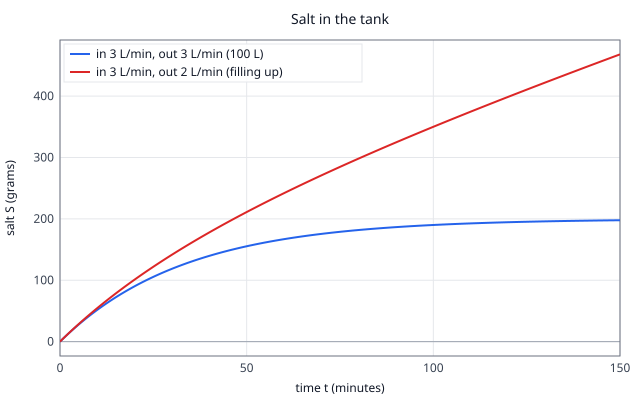

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [5]:
S2 = dsolve(d(S, t) == 6 - 2*S/(100 + t), S, t, 0, 0)
p = plot(S, S2, t, 0, 150);
p = legend(p, "in 3 L/min, out 3 L/min (100 L)", "in 3 L/min, out 2 L/min (filling up)");
labels(title(p, "Salt in the tank"), "time t (minutes)", "salt S (grams)")

In the second tank the salt keeps growing, because the tank does: the concentration $S/(100 + t)$ still tends to
2 g/L.

**Try this.** Check the concentration of the second tank at $t = 150$: `eval(subs(S2/(100 + t), t, 150))`.

In [6]:
eval(subs(S2/(100 + t), t, 150))

1.872

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

## 3. Transient and steady state: a driven circuit

A capacitor's charge $Q$ in a circuit with a resistor, driven by an alternating voltage, obeys (in suitable units)

$$Q' + \tfrac12 Q = 3\cos t, \qquad Q(0) = 0.$$

In [7]:
Q = dsolve(d(Q, t) + Q/2 == 3*cos(t), Q, t, 0, 0)

12*sin(t)/5-6*exp(-t/2)/5+6*cos(t)/5

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

Two parts again. The term $-\tfrac65e^{-t/2}$ is the **transient**: it comes from the start value and dies out. The
rest, $\tfrac{12}{5}\sin t + \tfrac65\cos t$, is the **steady state**: it oscillates with the driving frequency
forever, whatever the start. Written as one wave, $\tfrac{12}{5}\sin t + \tfrac65\cos t = A\sin(t + \varphi)$ with
amplitude $A = \sqrt{(12/5)^2 + (6/5)^2} = 6/\sqrt5$. The input is $3\cos t = 3\sin(t + \pi/2)$, so the response lags
behind it.

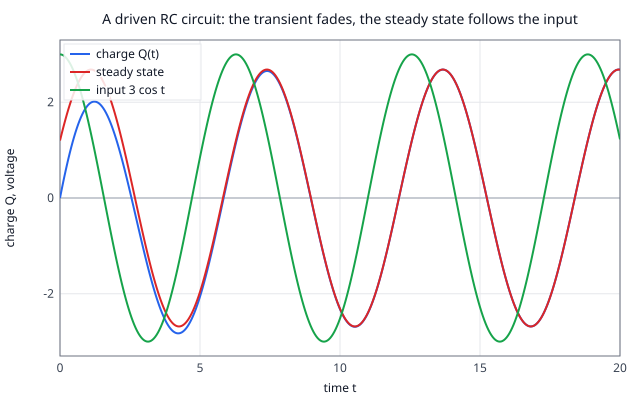

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [8]:
steady = 12*sin(t)/5 + 6*cos(t)/5;
p = plot(Q, steady, 3*cos(t), t, 0, 20);
p = legend(p, "charge Q(t)", "steady state", "input 3 cos t");
labels(title(p, "A driven RC circuit: the transient fades, the steady state follows the input"), "time t", "charge Q, voltage")

To find the steady state without the full solution, try $Q = a\cos t + b\sin t$ in the equation and match the
coefficients of $\cos t$ and $\sin t$. This **method of undetermined coefficients** returns in lesson 3.

**Try this.** Find $a$ and $b$ by hand: $Q' + Q/2 = (-a + b/2)\sin t + \ldots$. You should get $a = 6/5$, $b = 12/5$.

## 4. When there is no formula: Euler's method

Most equations cannot be solved by a formula. Then we follow the slope field in small steps of size $h$:

$$y_{n+1} = y_n + h\,f(x_n, y_n).$$

This is **Euler's method**. For $y' = y$, $y(0) = 1$, each step multiplies by $1 + h$. With $h = 1/10$, ten steps reach
$x = 1$:

In [9]:
iterate(1.1*y, y, 1.0, 10)
eval((1 + 1/10)^10)
eval(e)

[1.0, 1.1, 1.21, 1.331, 1.4641, 1.61051, 1.771561, 1.9487171, 2.14358881, 2.357947691, 2.5937424601]

> `iterate`: x0, f(x0), f(f(x0)), ...

2.5937424601

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

2.718281828459045

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

Ten steps give $2.594$ instead of $e = 2.718$. With $n$ steps, Euler gives $(1 + 1/n)^n$, which tends to $e$, but
slowly: the error is roughly proportional to $h$. Halving the step halves the error, which makes Euler's method a
**first-order** method:

In [10]:
[eval(e - (1 + 1/10)^10), eval(e - (1 + 1/20)^20), eval(e - (1 + 1/40)^40)]

[0.124539368359045, 0.06498412331462466, 0.033217990069072556]

The errors $0.125, 0.065, 0.033$ halve each time. Galileo's `odeplot` uses the fourth-order Runge–Kutta method instead,
whose error shrinks like $h^4$: halving the step divides the error by 16.

**Try this.** For a skydiver with air resistance, $v' = 9.8 - v/5$ (m/s, linear drag). Solve exactly, and find the
terminal speed.

In [11]:
dsolve(d(v, t) == 9.8 - v/5, v, t, 0, 0)

49.0-49.0*exp(-0.2*t)

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

## Summary

* Linear first-order: $y' + p\,y = q$. Multiply by $\mu = e^{\int p}$; then $(\mu y)' = \mu q$.
* General solution = a particular solution + the general solution of the homogeneous equation.
* Mixing: rate in minus rate out. Constant volume gives exponential approach to the inflow concentration.
* A driven stable system: transient (decays, depends on the start) + steady state (follows the input).
* Euler's method $y_{n+1} = y_n + hf$ has error proportional to $h$.

Next: [second-order equations](03-second-order.ipynb), where solutions can oscillate on their own.

## Exercises

1. **Integrating factor.** Solve $y' + y\tan x = \cos x$ (for $|x| < \pi/2$) by hand. Hint: $\mu = 1/\cos x$.
2. **Pollution.** A lake of $10^6$ m³ receives $10^4$ m³ of water a day carrying 5 g/m³ of a pollutant, and the same
   volume flows out. Starting clean, how long until the concentration reaches 4 g/m³?
3. **Cooling house.** The outside temperature is $10 + 5\sin t$ and a house follows Newton's law
   $T' = -(T - 10 - 5\sin t)$. Find the steady state and its amplitude.
4. **Euler by hand.** Do two Euler steps of size $h = 0.5$ for $y' = x + y$, $y(0) = 0$, and compare with the exact
   $y(1) = e - 2$.
5. **Bernoulli.** The substitution $u = 1/y$ turns $y' + y = y^2$ into a linear equation for $u$. Find it and solve,
   then compare with `dsolve(d(y, x) == y^2 - y, y, x)`.

## Hints and answers

* **Section 1, Try this.** $(e^{-x}y)' = xe^{-x}$, so $e^{-x}y = -(x + 1)e^{-x} + C$ and $y = Ce^x - x - 1$.
* **Section 2, Try this.** $S_2(150)/250 \approx 1.87$ g/L, on its way to 2. In fact $S_2/(100 + t) = 2 - 2\cdot10^6/(100 + t)^3$.
* **Section 3, Try this.** $Q' + Q/2 = (b + a/2)\cos t + (-a + b/2)\sin t = 3\cos t$, so $b + a/2 = 3$ and
  $-a + b/2 = 0$: $b = 2a$, $5a/2 = 3$, $a = 6/5$, $b = 12/5$.
* **Section 4, Try this.** $v = 49 - 49e^{-t/5}$; terminal speed 49 m/s, where $9.8 = v/5$.
* **Exercise 1.** $(y/\cos x)' = 1$, so $y = (x + C)\cos x$.
* **Exercise 2.** $c' = 0.01(5 - c)$ per day, $c = 5(1 - e^{-0.01t})$; $c = 4$ at $t = 100\log 5 \approx 161$ days.
* **Exercise 3.** Steady state $10 + \tfrac52(\sin t - \cos t)$, amplitude $5/\sqrt2 \approx 3.5$: the house swings
  less than the outside and lags by $\pi/4$.
* **Exercise 4.** $y_1 = 0$, $y_2 = 0 + 0.5(0.5 + 0) = 0.25$; exact $e - 2 \approx 0.718$. Euler is far off with such a
  big step.
* **Exercise 5.** $u' - u = -1$, $u = 1 + Ce^x$, $y = 1/(1 + Ce^x)$.

## Sources

1. W. E. Boyce, R. C. DiPrima and D. B. Meade, *Elementary Differential Equations and Boundary Value Problems*, 11th
   ed., Wiley (2017), sections 2.1, 2.3 and 2.7.
2. L. Euler, *Institutionum calculi integralis volumen primum*, St Petersburg (1768), part 2, chapter 7.
3. E. Hairer, S. P. Nørsett and G. Wanner, *Solving Ordinary Differential Equations I*, 2nd ed., Springer (1993),
   section II.1.